In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import re,json,nltk
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,accuracy_score,precision_score,recall_score,f1_score

from google.colab import drive
drive.mount('/content/drive')
path ='/content/drive/My Drive/Colab Notebooks/practice/demo/'

class color: # Text style
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip3 install sbnltk


In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/bangla_online_comments_dataset.csv',encoding='UTF-8')
data.head()

In [ ]:
data.columns

Index(['comment', 'Category', 'Gender', 'comment react number', 'label'], dtype='object')

In [ ]:
#printing some of the unprocessed reviews randomly

sample_data = [10,100,150,200,250,600,650,1000,40000]
for i in sample_data:
      print(data.comment[i],'\n','type:-- ',data.label[i],'\n')

In [ ]:
#stat of labeling

print("Total Reviews:",len(data),
      "\nTotal sexual :",len(data[data.label =='sexual']),
      "\nTotal trolling :",len(data[data.label =='troll']),
      "\nTotal religious :",len(data[data.label=='religious']),
      "\nTotal threating :",len(data[data.label=='threat']),
      "\nTotal Neutral :",len(data[data.label =='not bully']))

Total Reviews: 44001 
Total sexual : 8928 
Total trolling : 10462 
Total religious : 7577 
Total threating : 1694 
Total Neutral : 15340


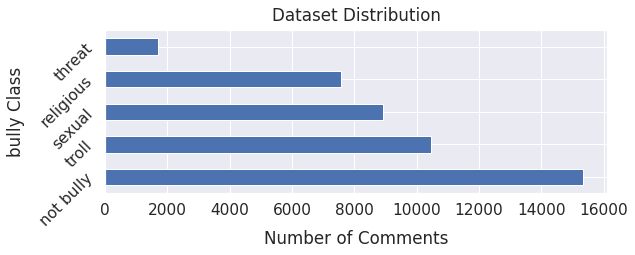

In [ ]:
sns.set(font_scale=1.4)
data['label'].value_counts().plot(kind='barh', figsize=(9, 3))
plt.xlabel("Number of Comments", labelpad=12)
plt.ylabel("bully Class", labelpad=12)
plt.yticks(rotation = 45)
plt.title("Dataset Distribution", y=1.02);

Data cleaning


In [ ]:
#punctuation remove
from sbnltk.Preprocessor import preprocessor


p=preprocessor()


def process_comments(comment):
  #comment = re.sub('[^\u0980-\u09FF]',' ',str(comment)) #removing unnecessary punctuation
  comment = p.punctuation_remove(comment)
  # comment = p.dust_removal(comment)

  comment = p.stopword_remove(comment)
  comment = p.word_normalize(comment)
  return comment


def process_comments2(comment):
  comment = re.sub('[^\u0980-\u09FF]',' ',str(comment)) #removing unnecessary punctuation
  return comment





Downloading...
From: https://drive.google.com/uc?id=142XvJg9xdpgzuYD31Y4pm-ZVdMaWmtuq
To: /usr/local/lib/python3.7/dist-packages/sbnltk/dataset/download_link.txt
100%|██████████| 1.66k/1.66k [00:00<00:00, 1.55MB/s]
Downloading...
From: https://drive.google.com/uc?id=1UIR2arP_6Fm0MqJVbcG2Q9iLCnjQriDB
To: /usr/local/lib/python3.7/dist-packages/sbnltk/dataset/bangla_word_list.txt
100%|██████████| 15.4M/15.4M [00:00<00:00, 93.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1e4x5FQrdGyEfBBzQ_DOJ9wBxZZ1F7bx7
To: /usr/local/lib/python3.7/dist-packages/sbnltk/dataset/stopword_list.txt
100%|██████████| 4.77k/4.77k [00:00<00:00, 6.74MB/s]


In [ ]:
# Apply the function into the dataframe
data['cleaned'] = data['comment'].apply(process_comments)

data['cleaned'] = data['comment'].apply(process_comments2)




# print some cleaned reviews from the dataset
sample_data = [4,10,100,25,854,966,1500,1589,1700,2000,2500,4000,4500,40000]
for i in sample_data:
     print('Original:\n',data.comment[i],'\nCleaned:\n',
           data.cleaned[i],'\n','type of bully:-- ',data.label[i],'\n')

removing low length data

In [ ]:
# Length of each Reveiws
data['length'] = data['cleaned'].apply(lambda x:len(x.split()))

# Remove the reviews with least words
dataset = data.loc[data.length>1]
dataset = dataset.reset_index(drop = True)
print("After Cleaning:","\nRemoved {} Small Reviews".format(len(data)-len(dataset)),
      "\nTotal comment:",len(dataset))



After Cleaning: 
Removed 1247 Small Reviews 
Total comment: 42754


dataset summary


In [ ]:
def data_summary(dataset):
    documents = []
    words = []
    u_words = []
    total_u_words = [word.strip().lower() for t in list(dataset.cleaned) for word in t.strip().split()]
    class_label= [k for k,v in dataset.label.value_counts().to_dict().items()]

    #find word list
    for label in class_label:
        word_list = [word.strip().lower() for t in list(dataset[dataset.label==label].cleaned) for word in t.strip().split()]
        counts = dict()
        for word in word_list:
                counts[word] = counts.get(word, 0)+1
        # sort the dictionary of word list
        ordered = sorted(counts.items(), key= lambda item: item[1],reverse = True)
        # Documents per class
        documents.append(len(list(dataset[dataset.label==label].cleaned)))
        # Total Word per class
        words.append(len(word_list))
        # Unique words per class
        u_words.append(len(np.unique(word_list)))
        print("\nClass Name : ",label)
        print("Number of Documents:{}".format(len(list(dataset[dataset.label==label].cleaned))))
        print("Number of Words:{}".format(len(word_list)))
        print("Number of Unique Words:{}".format(len(np.unique(word_list))))
        print("Most Frequent Words:\n")
        for k,v in ordered[:10]:
              print("{}\t{}".format(k,v))
    print("Total Number of Unique Words:{}".format(len(np.unique(total_u_words))))

    return documents,words,u_words,class_label

#call the fucntion
documents,words,u_words,class_names = data_summary(dataset)




Class Name :  not bully
Number of Documents:14550
Number of Words:186637
Number of Unique Words:23054
Most Frequent Words:

না	2785
আল্লাহ	1865
করে	1806
ভাই	1733
আপনার	1479
হিরো	1436
আলম	1375
কি	1292
এই	1268
আর	1251

Class Name :  troll
Number of Documents:10212
Number of Words:153113
Number of Unique Words:21480
Most Frequent Words:

না	3265
কি	1798
করে	1634
আর	1345
এই	1301
হিরো	1031
তো	1016
তুই	909
কে	902
বিশ্বাস	881

Class Name :  sexual
Number of Documents:8775
Number of Words:176083
Number of Unique Words:22747
Most Frequent Words:

না	3673
করে	1879
কি	1678
মাগি	1489
আর	1408
বিশ্বাস	1343
তুই	1333
এই	1198
আমি	1142
তোর	1130

Class Name :  religious
Number of Documents:7531
Number of Words:199631
Number of Unique Words:20375
Most Frequent Words:

নাস্তিক	5289
না	4965
করে	2615
বিশ্বাস	2262
কি	1994
আর	1958
তুই	1720
আল্লাহ	1638
এই	1567
যে	1497

Class Name :  threat
Number of Documents:1686
Number of Words:29082
Number of Unique Words:6422
Most Frequent Words:

জুতা	761
না	501
করে	346
এ

Dataset summary visualization

In [ ]:
data_matrix = pd.DataFrame({'Total Documents':documents,
                            'Total Words':words,
                            'Unique Words':u_words,
                            'Class Names':class_names})
df = pd.melt(data_matrix, id_vars="Class Names", var_name="Category", value_name="Values")
print(df)

   Class Names         Category  Values
0    not bully  Total Documents   14550
1        troll  Total Documents   10212
2       sexual  Total Documents    8775
3    religious  Total Documents    7531
4       threat  Total Documents    1686
5    not bully      Total Words  186637
6        troll      Total Words  153113
7       sexual      Total Words  176083
8    religious      Total Words  199631
9       threat      Total Words   29082
10   not bully     Unique Words   23054
11       troll     Unique Words   21480
12      sexual     Unique Words   22747
13   religious     Unique Words   20375
14      threat     Unique Words    6422


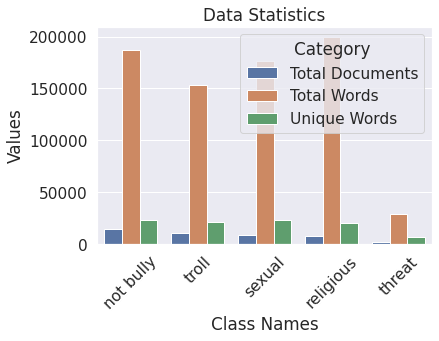

In [ ]:
plt.figure(figsize=(6, 4))
ax = plt.subplot()

sns.barplot(data=df,x='Class Names', y='Values' ,hue='Category')
ax.set_xlabel('Class Names')
ax.set_title('Data Statistics')

ax.xaxis.set_ticklabels(class_names, rotation=45);
plt.savefig('data_statistics.png',dpi = 600,bbox_inches = 'tight')

Review Length Distribution

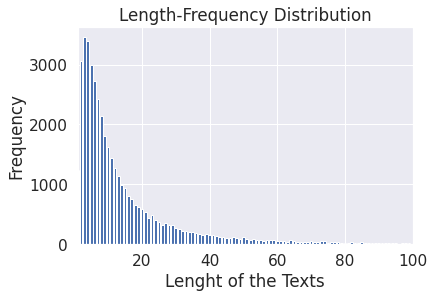

Maximum Length of a review: 241
Average Length of a reviews: 17.0


In [ ]:
# Calculate the Review of each of the Review
data['ReviewLength'] = data.cleaned.apply(lambda x:len(x.split()))
frequency = dict()
for i in data.ReviewLength:
    frequency[i] = frequency.get(i, 0)+1

plt.bar(frequency.keys(), frequency.values(), color ="b")
plt.xlim(1, 100)
# in this notbook color is not working but it should work.
plt.xlabel('Lenght of the Texts')
plt.ylabel('Frequency')
plt.title('Length-Frequency Distribution')
plt.savefig('length_dist.png',dpi = 600,bbox_inches = 'tight')
plt.show()
print(f"Maximum Length of a review: {max(data.ReviewLength)}")
print(f"Average Length of a reviews: {round(np.mean(data.ReviewLength),0)}")

In [ ]:
data.head(10)

In [ ]:
#finding the count of different  labels
data['label'].value_counts()


not bully    15340
troll        10462
sexual        8928
religious     7577
threat        1694
Name: label, dtype: int64

label encoding function

In [ ]:
def label_encoding(sentiment,bool):
  le=LabelEncoder()
  le.fit(sentiment)
  encoded_labels=le.transform(sentiment)
  labels=np.array(encoded_labels)
  class_names = le.classes_
  if bool==True:
      print("\n\t\t\t===== Label Encoding =====","\nClass Names:-->",le.classes_)
      for i in sample_data:
            print(sentiment[i],' ', encoded_labels[i],'\n')

  return labels


dataset spilting function


In [ ]:
def dataset_split(feature_space,sentiment):
   X_train,X_test,y_train,y_test = train_test_split(feature_space,sentiment,train_size = 0.8,
                                                  test_size = 0.2,random_state =0)
   print("Feature Size :======>",X_train.shape[1])
   print("\nDataset Distribution:\n")
   print("\tSet Name","\t\tSize")
   print("\t========\t\t======")

   print("\tFull\t\t\t",feature_space.shape[0],
        "\n\tTraining\t\t",X_train.shape[0],
        "\n\tTest\t\t\t",X_test.shape[0])

   return X_train,X_test,y_train,y_test

In [ ]:
dataset.cleaned = dataset.cleaned.apply(lambda x:x.replace('\n',' '))

In [ ]:
data.cleaned

Feature extraction using TF-IDF

In [ ]:
## ##### Unigram Tf-idf value calculation

def calc_unigram_tfidf(reviews):

    tfidf = TfidfVectorizer(use_idf=True,tokenizer=lambda x: x.split())
    X = tfidf.fit_transform(reviews)

    return tfidf,X

In [ ]:
##Bi-gram Tf-idf value calculation
def calc_bigram_tfidf(reviews):

    tfidf = TfidfVectorizer(ngram_range=(1,2),use_idf=True,tokenizer=lambda x: x.split())
    X = tfidf.fit_transform(reviews)

    return tfidf,X

In [ ]:
##Tri-gram Tf-idf value calculation
def calc_trigram_tfidf(reviews):

    tfidf = TfidfVectorizer(ngram_range=(1,3),use_idf=True,tokenizer=lambda x: x.split())
    X = tfidf.fit_transform(reviews)

    return tfidf,X

In [ ]:
#printing tf-idf value
def show_tfidf(tfidf_instance,samp_review):

    print("Sample Review: ",samp_review)
    first_vector = tfidf_instance.transform([samp_review])
    df = pd.DataFrame(first_vector.T.todense(), index=tfidf_instance.get_feature_names(), columns=["tfidf"])
    a = df.sort_values(by=["tfidf"],ascending=False)
    print(a[0:len(samp_review.split())])

demo of feature extraction


In [ ]:
text = 'মামুন  ফালতু'
cv,feature_vector = calc_unigram_tfidf(data.cleaned)

print("Shape of TF-IDF Corpus =====>",feature_vector.shape,'\n')
show_tfidf(cv,text)




Shape of TF-IDF Corpus =====> (44001, 55874) 

Sample Review:  মামুন স্যার ফালতু
          tfidf
মামুন  0.738364
স্যার  0.505677
ফালতু  0.446217


/usr/local/lib/python3.7/dist-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function get_feature_names is deprecated; get_feature_names is deprecated in 1.0 and will be removed in 1.2. Please use get_feature_names_out instead.
  warnings.warn(msg, category=FutureWarning)


In [ ]:
 !pip uninstall scikit-learn -y
 !pip install scikit-learn==1.0
 !pip install lazypredict

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report,accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import average_precision_score,roc_auc_score, roc_curve, precision_recall_curve

Classifier for unigrams

In [ ]:
def ml_models_for_unigram_tfidf():

    lr_model = LogisticRegression(random_state = 123)
    dt_model = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
    rf_model = RandomForestClassifier(n_estimators=100, criterion ='entropy', random_state = 0)
    mnb_model = MultinomialNB(alpha=0.15)
    knn_model = KNeighborsClassifier(n_neighbors=3, metric = 'minkowski')
    lsvm_model = SVC(kernel = 'linear',C = 0.2, probability=True, random_state = 0)


    model_names = ['Logistic Regression','Decision Tree','Random Forest','Naive Bayes','KNN','Linear SVM']
    # Create list of models
    ml_models = [lr_model,dt_model,rf_model,mnb_model,knn_model,lsvm_model]
    return ml_models,model_names

Classifiers for Bigram

In [ ]:
def ml_models_for_bigram_tfidf():


    lr_model = LogisticRegression(random_state = 123)
    dt_model = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
    rf_model = RandomForestClassifier(n_estimators=100, criterion ='entropy', random_state = 0)
    mnb_model = MultinomialNB(alpha=0.008)
    knn_model = KNeighborsClassifier(n_neighbors=2, metric = 'minkowski')
    lsvm_model = SVC(kernel = 'linear',C = 0.3, probability=True, random_state = 0)
    model_names = ['Logistic Regression','Decision Tree','Random Forest','Naive Bayes','KNN','Linear SVM']
    ml_models = [lr_model,dt_model,rf_model,mnb_model,knn_model,lsvm_model]
    return ml_models,model_names

Classifiers for Trigram

In [ ]:
def ml_models_for_trigram_tfidf():


    lr_model = LogisticRegression(random_state = 123)
    dt_model = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
    rf_model = RandomForestClassifier(n_estimators=100, criterion ='entropy', random_state = 0)
    mnb_model = MultinomialNB(alpha=0.001)
    knn_model = KNeighborsClassifier(n_neighbors=2, metric = 'minkowski')
    lsvm_model = SVC(kernel = 'linear',C = 0.3, probability=True, random_state = 0)
    model_names = ['Logistic Regression','Decision Tree','Random Forest','Naive Bayes','KNN','Linear SVM']
    #create a list of models
    ml_models = [lr_model,dt_model,rf_model,mnb_model,knn_model,lsvm_model]
    return ml_models,model_names

machine learning model development using unigram feature

In [ ]:
cv,feature_vector = calc_unigram_tfidf(data.cleaned)
# Encode the labels
lables = label_encoding(data.label,False)

# Split the Feature into train and test set
X_train,X_test,y_train,y_test = dataset_split(feature_space=feature_vector,sentiment=lables)
